# Complete Project Workflow — Used Smartphone Price Prediction

Run this notebook from top to bottom in one kernel. Download the dataset first and save it as `data/used_phones.csv`. The individual stage notebooks are also provided for focused study.

---

# Included stage notebook: `01_data_understanding.ipynb`

# Stage 1–2: Dataset Collection and Understanding
## Objective
Download the dataset from Kaggle, place it at `data/used_phones.csv`, and inspect its shape, columns, data types, missing values and target.

**Dataset:** https://www.kaggle.com/datasets/ahsan81/used-handheld-device-data

Do not assume a normalized target is an INR amount. Check the dataset documentation.

In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
import pandas as pd
import numpy as np

DATA_PATH ="used_phones.csv"
df = pd.read_csv(DATA_PATH)
df.head()


,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,2020,127,4.307572,4.715100
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,2020,325,5.162097,5.519018
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,2020,162,5.111084,5.884631
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,2020,345,5.135387,5.630961
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,2020,293,4.389995,4.947837


In [2]:
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
print(df.dtypes)
print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False))
print("\\nDuplicate rows:", df.duplicated().sum())

Rows and columns: (3454, 15)
\nColumn names:
['device_brand', 'os', 'screen_size', '4g', '5g', 'rear_camera_mp', 'front_camera_mp', 'internal_memory', 'ram', 'battery', 'weight', 'release_year', 'days_used', 'normalized_used_price', 'normalized_new_price']
\nData types:
device_brand                 str
os                           str
screen_size              float64
4g                           str
5g                           str
rear_camera_mp           float64
front_camera_mp          float64
internal_memory          float64
ram                      float64
battery                  float64
weight                   float64
release_year               int64
days_used                  int64
normalized_used_price    float64
normalized_new_price     float64
dtype: object
\nMissing values:


rear_camera_mp           179
weight                     7
battery                    6
internal_memory            4
ram                        4
front_camera_mp            2
device_brand               0
4g                         0
5g                         0
os                         0
screen_size                0
release_year               0
days_used                  0
normalized_used_price      0
normalized_new_price       0
dtype: int64

\nDuplicate rows: 0


In [3]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
device_brand,3454,34,Others,502,NaN,NaN,NaN,NaN,NaN,NaN,NaN
os,3454,4,Android,3214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
screen_size,3454.0,NaN,NaN,NaN,13.713115,3.80528,5.08,12.7,12.83,15.34,30.71
4g,3454,2,yes,2335,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5g,3454,2,no,3302,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rear_camera_mp,3275.0,NaN,NaN,NaN,9.460208,4.815461,0.08,5.0,8.0,13.0,48.0
front_camera_mp,3452.0,NaN,NaN,NaN,6.554229,6.970372,0.0,2.0,5.0,8.0,32.0
internal_memory,3450.0,NaN,NaN,NaN,54.573099,84.972371,0.01,16.0,32.0,64.0,1024.0
ram,3450.0,NaN,NaN,NaN,4.036122,1.365105,0.02,4.0,4.0,4.0,12.0
battery,3448.0,NaN,NaN,NaN,3133.402697,1299.682844,500.0,2100.0,3000.0,4000.0,9720.0


## Identify the target column
The target is the used/resale price. In the recommended dataset it is commonly named `normalized_used_price`. Verify this in the dataset documentation.

In [4]:
TARGET = "normalized_used_price"  # Change this if your CSV uses a different target name.
if TARGET not in df.columns:
    raise ValueError(f"Target {TARGET!r} not found. Available columns: {df.columns.tolist()}")
display(df[TARGET].describe())
print("Target dtype:", df[TARGET].dtype)

count    3454.000000
mean        4.364712
std         0.588914
min         1.536867
25%         4.033931
50%         4.405133
75%         4.755700
max         6.619433
Name: normalized_used_price, dtype: float64

Target dtype: float64


## What to record in your project report
- Number of records and features.
- Exact target column and its unit/meaning.
- Columns with missing values.
- Duplicate-row count.
- Any suspicious values that need checking.

---

# Included stage notebook: `02_data_cleaning.ipynb`

# Stage 3: Data Cleaning
We will remove exact duplicates, convert the target to numeric, and remove rows with missing or non-positive target values. We will not fill feature missing values here: imputers must be fitted on training data only to prevent data leakage.

In [5]:
from pathlib import Path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
import pandas as pd
DATA_PATH ="used_phones.csv"
df = pd.read_csv(DATA_PATH)
TARGET = "normalized_used_price"  # Confirm this against your dataset.
if TARGET not in df.columns:
    raise ValueError(f"Target {TARGET!r} not found. Available columns: {df.columns.tolist()}")
df.shape


(3454, 15)

In [6]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates().copy()
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
before = len(df)
df = df.dropna(subset=[TARGET])
df = df[df[TARGET] > 0].copy()
print("Rows removed for invalid target:", before - len(df))
print("Clean shape:", df.shape)

Duplicates before: 0
Rows removed for invalid target: 0
Clean shape: (3454, 15)


In [7]:
# Review possible numeric outliers; do not delete them automatically.
display(df.select_dtypes(include="number").describe(percentiles=[.01,.25,.5,.75,.99]).T)

,count,mean,std,min,1%,25%,50%,75%,99%,max
screen_size,3454.0,13.713115,3.805280,5.080000,5.180000,12.700000,12.830000,15.340000,25.500000,30.710000
rear_camera_mp,3275.0,9.460208,4.815461,0.080000,0.300000,5.000000,8.000000,13.000000,21.200000,48.000000
front_camera_mp,3452.0,6.554229,6.970372,0.000000,0.000000,2.000000,5.000000,8.000000,32.000000,32.000000
internal_memory,3450.0,54.573099,84.972371,0.010000,0.100000,16.000000,32.000000,64.000000,512.000000,1024.000000
ram,3450.0,4.036122,1.365105,0.020000,0.137800,4.000000,4.000000,4.000000,8.000000,12.000000
battery,3448.0,3133.402697,1299.682844,500.000000,1024.700000,2100.000000,3000.000000,4000.000000,7806.360000,9720.000000
weight,3447.0,182.751871,88.413228,69.000000,89.246000,142.000000,160.000000,185.000000,590.400000,855.000000
release_year,3454.0,2015.965258,2.298455,2013.000000,2013.000000,2014.000000,2015.500000,2018.000000,2020.000000,2020.000000
days_used,3454.0,674.869716,248.580166,91.000000,131.120000,533.500000,690.500000,868.750000,1085.000000,1094.000000
normalized_used_price,3454.0,4.364712,0.588914,1.536867,2.690605,4.033931,4.405133,4.755700,5.605750,6.619433


In [8]:
# Save cleaned data in the project's data folder.
CLEAN_PATH = DATA_DIR / "used_phones_cleaned.csv"
df.to_csv(CLEAN_PATH, index=False)
print("Saved:", CLEAN_PATH.resolve())

Saved: C:\Users\Dudekula Alla Rasool\OneDrive\Desktop\ML PROJECT_1\Used_Smartphone_Price_Prediction\data\used_phones_cleaned.csv


## Cleaning decisions
Document any additional corrections you make. Do not remove unusual but plausible prices without checking whether they are genuine observations or data errors.

---

# Included stage notebook: `03_exploratory_data_analysis.ipynb`

# Stage 4: Exploratory Data Analysis (EDA)
EDA helps us understand the target distribution and relationships between phone specifications and used price.

In [9]:
from pathlib import Path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = DATA_DIR / "used_phones_cleaned.csv"
df = pd.read_csv(DATA_PATH)
TARGET = "normalized_used_price"


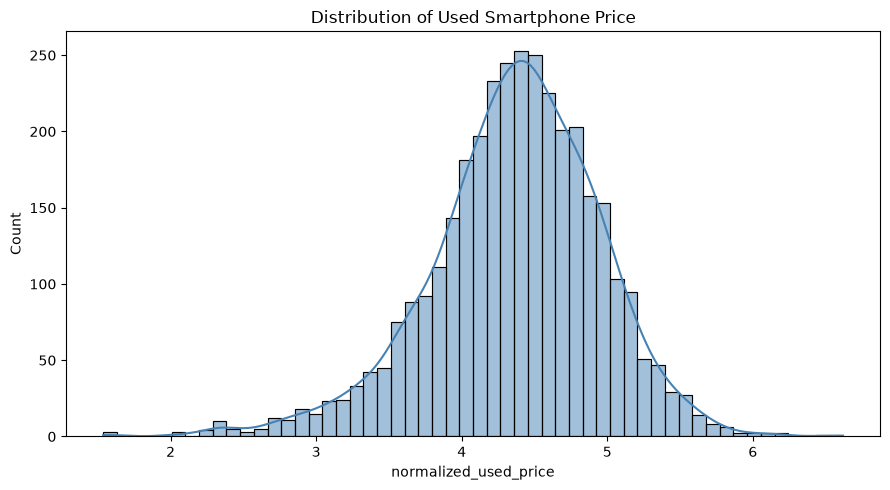

In [10]:
plt.figure(figsize=(9,5))
sns.histplot(df[TARGET], kde=True, color="steelblue")
plt.title("Distribution of Used Smartphone Price")
plt.xlabel(TARGET)
plt.tight_layout()
plt.show()

In [11]:
brand_col = next((c for c in df.columns if c.lower() in {"brand_name","brand","manufacturer"}), None)
if brand_col:
    top_brands = df[brand_col].value_counts().head(15).index
    plt.figure(figsize=(10,6))
    sns.countplot(data=df[df[brand_col].isin(top_brands)], y=brand_col,
                  order=df[brand_col].value_counts().head(15).index, color="steelblue")
    plt.title("Most Frequent Smartphone Brands")
    plt.tight_layout()
    plt.show()
else:
    print("No recognizable brand column found.")

No recognizable brand column found.


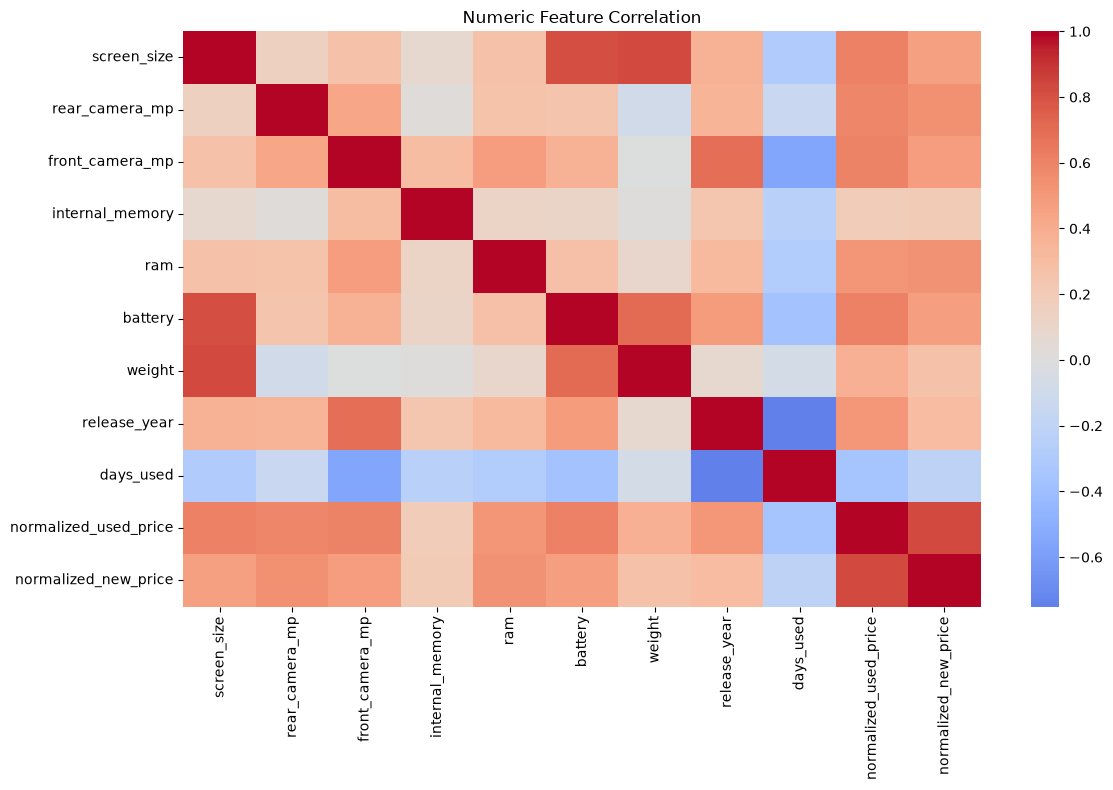

In [12]:
numeric = df.select_dtypes(include="number")
plt.figure(figsize=(12,8))
sns.heatmap(numeric.corr(), cmap="coolwarm", center=0)
plt.title("Numeric Feature Correlation")
plt.tight_layout()
plt.show()

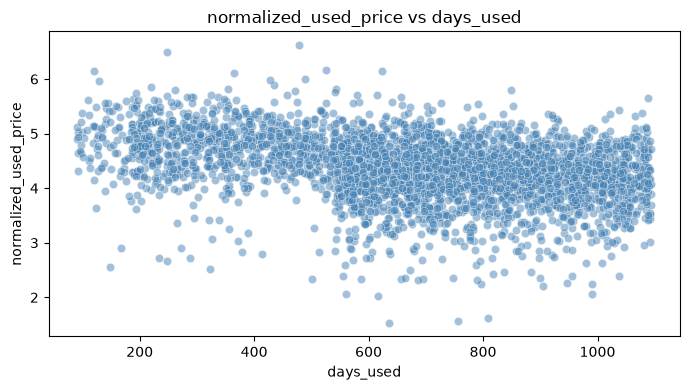

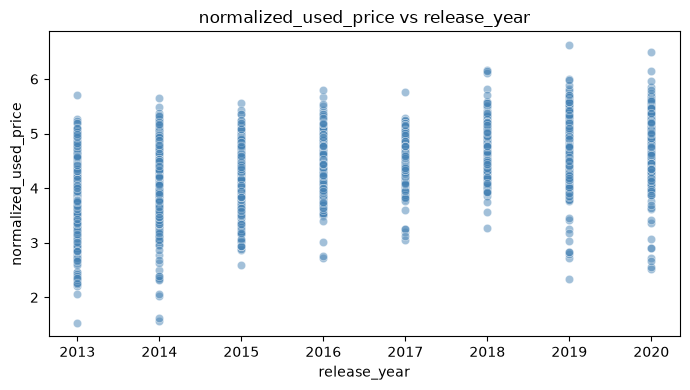

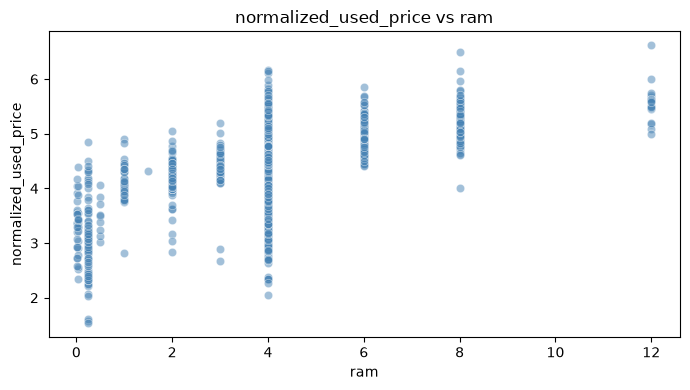

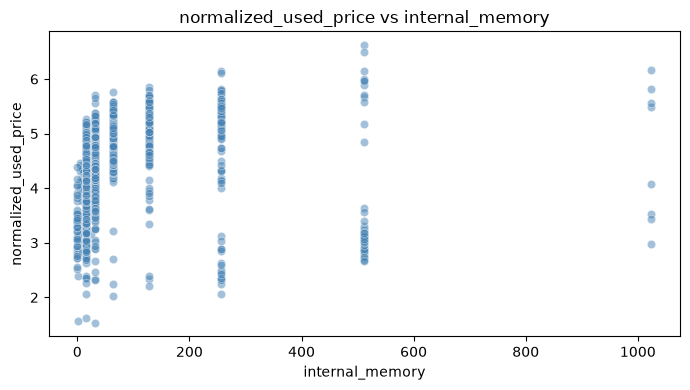

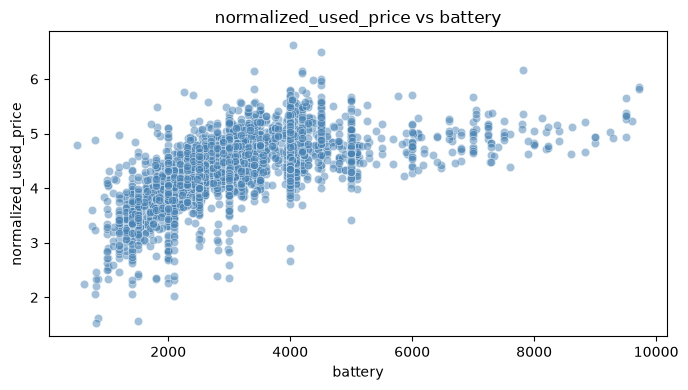

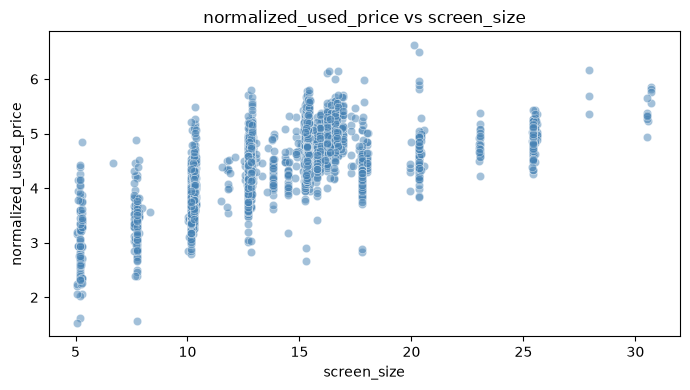

In [13]:
for feature in ["days_used","release_year","ram","internal_memory","battery","screen_size"]:
    if feature in df.columns:
        plt.figure(figsize=(7,4))
        sns.scatterplot(data=df, x=feature, y=TARGET, alpha=.5, color="steelblue")
        plt.title(f"{TARGET} vs {feature}")
        plt.tight_layout()
        plt.show()

## EDA questions to answer
1. Which brands are most represented?
2. How is the target price distributed?
3. Does longer usage appear associated with a lower used price?
4. Which hardware features appear associated with price?
5. Are there outliers or imbalanced brand categories?

Write observations based on your actual charts; do not invent findings.

---

# Included stage notebook: `04_feature_engineering.ipynb`

# Stage 5: Feature Engineering
Feature engineering creates useful input variables from existing data. We must only create features that are supported by the dataset and available at prediction time.

In [14]:
from pathlib import Path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
import pandas as pd
df = pd.read_csv(DATA_DIR / "used_phones_cleaned.csv")
df.head()


,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,2020,127,4.307572,4.715100
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,2020,325,5.162097,5.519018
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,2020,162,5.111084,5.884631
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,2020,345,5.135387,5.630961
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,2020,293,4.389995,4.947837


## Example: derive phone age from release year
Use a consistent reference year. The notebook uses the current year dynamically. Check the dataset's release-year values first. This feature is optional and should be retained only if it makes sense for the dataset.

In [15]:
from datetime import date
if "release_year" in df.columns:
    current_year = date.today().year
    df["phone_age_years"] = (current_year - pd.to_numeric(df["release_year"], errors="coerce")).clip(lower=0)
    display(df[["release_year", "phone_age_years"]].head())
    # Avoid redundant inputs: retain phone_age_years and remove release_year.
    df = df.drop(columns=["release_year"])
else:
    print("release_year not present; skip phone_age_years.")

,release_year,phone_age_years
0,2020,6
1,2020,6
2,2020,6
3,2020,6
4,2020,6


## Avoid data leakage
Do not include the used price in X. Do not derive features using information that would only be known after the resale transaction. Do not create made-up battery health or physical condition values when the dataset does not contain them.

In [16]:
TARGET = "normalized_used_price"
X = df.drop(columns=[TARGET])
y = df[TARGET]
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Features:", X.columns.tolist())

Feature shape: (3454, 14)
Target shape: (3454,)
Features: ['device_brand', 'os', 'screen_size', '4g', '5g', 'rear_camera_mp', 'front_camera_mp', 'internal_memory', 'ram', 'battery', 'weight', 'days_used', 'normalized_new_price', 'phone_age_years']


In [17]:
# Save the engineered working dataset if you decide to keep the derived feature.
df.to_csv(DATA_DIR / "used_phones_features.csv", index=False)
print("Saved engineered dataset.")

Saved engineered dataset.


---

# Included stage notebook: `05_preprocessing_and_modeling.ipynb`

# Stage 6–8: Preprocessing, Train-Test Split and Model Building
We use a scikit-learn Pipeline so missing-value imputation, scaling and one-hot encoding are learned from training data only. This prevents preprocessing leakage.

In [18]:
from pathlib import Path
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

df = pd.read_csv(DATA_DIR / "used_phones_features.csv")
TARGET = "normalized_used_price"
if TARGET not in df.columns:
    raise ValueError(f"Target {TARGET!r} not found. Available columns: {df.columns.tolist()}")
y = pd.to_numeric(df[TARGET], errors="coerce")
X = df.drop(columns=[TARGET])
valid = y.notna() & (y > 0)
X, y = X.loc[valid].copy(), y.loc[valid].copy()
id_cols = [c for c in X.columns if c.strip().lower() in {"id", "phone_id", "listing_id", "record_id", "url"}]
X = X.drop(columns=id_cols)
constant_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
X = X.drop(columns=constant_cols)
if X.empty:
    raise ValueError("No usable feature columns remain after removing IDs and constant columns.")
if len(X) < 10:
    raise ValueError("At least 10 valid rows are recommended for train/test split and 5-fold cross-validation.")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=42)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)


Train shape: (2763, 14) Test shape: (691, 14)


In [19]:
numeric_cols = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_cols),
    ("categorical", categorical_pipe, categorical_cols)
], sparse_threshold=0)


In [20]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=12, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}
from sklearn.model_selection import cross_val_score

cv_results = []
for name, estimator in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", estimator)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5,
                             scoring="neg_root_mean_squared_error", n_jobs=-1)
    cv_results.append({"Model": name, "CV_RMSE": float(-scores.mean()), "CV_Std": float(scores.std())})
cv_results_df = pd.DataFrame(cv_results).sort_values("CV_RMSE")
display(cv_results_df)


,Model,CV_RMSE,CV_Std
3,Gradient Boosting,0.226157,0.006898
2,Random Forest,0.232753,0.006071
0,Linear Regression,0.237988,0.009103
1,Decision Tree,0.302679,0.005494


Choose the model with the lowest average cross-validation RMSE on the training partition. The test partition must remain untouched until final evaluation.

---

# Included stage notebook: `06_evaluation_and_tuning.ipynb`

# Stage 9–10: Evaluation and Hyperparameter Tuning
Metrics: MAE, MSE, RMSE and R². Regression tasks do not use classification accuracy.

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [22]:
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
])
param_dist = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}
search = RandomizedSearchCV(
    rf_pipe, param_distributions=param_dist, n_iter=8, cv=5,
    scoring="neg_root_mean_squared_error", random_state=42,
    n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)
print("Tuned Random Forest CV RMSE:", -search.best_score_)
print("Best parameters:", search.best_params_)

# Compare tuned RF with the best baseline model using training CV scores only.
best_baseline_name = cv_results_df.iloc[0]["Model"]
baseline_model = Pipeline([("prep", preprocessor), ("model", models[best_baseline_name])])
baseline_model.fit(X_train, y_train)
baseline_cv_rmse = float(cv_results_df.iloc[0]["CV_RMSE"])
tuned_cv_rmse = float(-search.best_score_)
if tuned_cv_rmse <= baseline_cv_rmse:
    best_model = search.best_estimator_
    selected_model_name = "Tuned Random Forest"
else:
    best_model = baseline_model
    selected_model_name = best_baseline_name
print("Selected model:", selected_model_name)


Fitting 5 folds for each of 8 candidates, totalling 40 fits


Tuned Random Forest CV RMSE: 0.23080819757264986
Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_depth': 10}
Selected model: Gradient Boosting


In [23]:
predictions = best_model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
metrics = {
    "MAE": float(mean_absolute_error(y_test, predictions)),
    "MSE": float(mse),
    "RMSE": float(np.sqrt(mse)),
    "R2": float(r2_score(y_test, predictions))
}
print("Held-out test metrics:", metrics)
metrics


Held-out test metrics: {'MAE': 0.17563047089305528, 'MSE': 0.0473718106856367, 'RMSE': 0.21765066203813097, 'R2': 0.8540243093918422}


{'MAE': 0.17563047089305528,
 'MSE': 0.0473718106856367,
 'RMSE': 0.21765066203813097,
 'R2': 0.8540243093918422}

In [24]:
comparison = pd.DataFrame({"actual": y_test, "predicted": predictions})
comparison.head(10)

,actual,predicted
511,3.974246,3.987687
51,5.001191,4.844664
1171,4.562054,4.274621
2282,4.176232,4.181034
557,3.156149,3.696142
764,3.777119,4.085246
1200,4.932890,4.655272
192,5.120924,4.953250
2259,4.044103,4.151136
1991,4.318687,4.574957


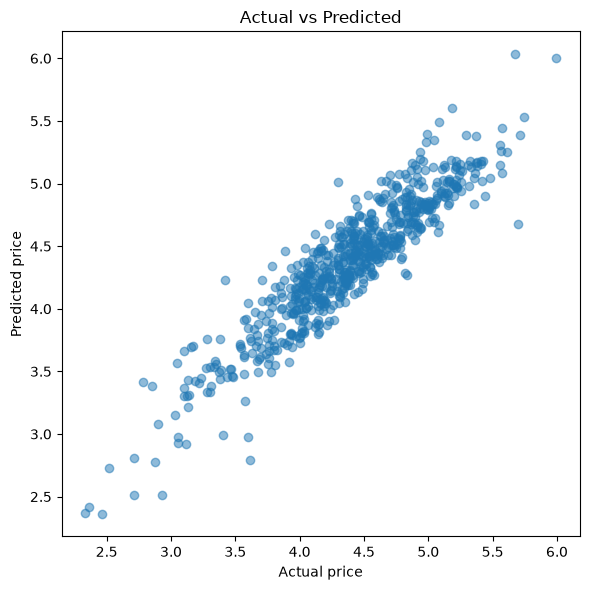

In [25]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, predictions, alpha=.5)
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs Predicted")
plt.tight_layout()
plt.show()

## Interpret results
- Lower MAE/RMSE is better.
- R² closer to 1 is generally better; negative R² means the model performs worse than predicting the test-set mean.
- Explain errors in the target's unit.
- Do not report results until you have run the notebook on your real downloaded dataset.

---

# Included stage notebook: `07_prediction_and_deployment.ipynb`

# Stage 11–12: Save the Model, Predict and Deploy
This notebook demonstrates saving a fitted pipeline and launching the Streamlit application.

In [26]:
import json
import joblib

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(best_model, MODEL_DIR / "used_smartphone_price_model.joblib")
metadata = {
    "target_column": TARGET,
    "feature_columns": X.columns.tolist(),
    "numeric_features": numeric_cols,
    "categorical_features": categorical_cols,
    "model_name": selected_model_name,
    "test_metrics": metrics,
    "target_note": "Verify the target unit in the dataset documentation; normalized_used_price is not necessarily INR."
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved model and metadata to:", MODEL_DIR)


Saved model and metadata to: c:\Users\Dudekula Alla Rasool\OneDrive\Desktop\ML PROJECT_1\Used_Smartphone_Price_Prediction\models


## Launch the app
From a terminal opened at the project root (not inside `notebooks`), run:

```bash
streamlit run app.py
```

The app reads the saved model and builds input controls for the features used during training.

## Final project checklist
- [ ] Dataset source and license checked.
- [ ] Target definition and unit verified.
- [ ] Data inspection and cleaning completed.
- [ ] EDA charts interpreted.
- [ ] Feature engineering justified.
- [ ] Preprocessing pipeline fitted only on training data.
- [ ] Multiple regression algorithms compared.
- [ ] Hyperparameter tuning completed using training data.
- [ ] Final test metrics recorded.
- [ ] Model saved and Streamlit app tested.
- [ ] README updated with real results and limitations.
- [ ] GitHub repository prepared.